# AI Model Experiment & Evaluation
**Starter Notebook**

Notebook ini adalah kerangka awal untuk membandingkan dua pendekatan AI dalam menyelesaikan task sentiment analysis ulasan pelanggan:
1. Model klasik Machine Learning (Scikit-learn)
2. LLM API (Gemini)

Isi tiap section sesuai instruksi di Assignment Brief. Jangan ubah struktur section, tapi silakan tambah cell baru di dalam tiap section jika diperlukan.

> 🔧 **Catatan Penyesuaian Dataset**
>
> Notebook ini menggunakan dataset `customer_reviews_sentiment.csv` dengan kolom `review_text` dan `sentiment` (nilai: `positif`/`negatif`).
>
> Apabila dataset final berbeda dari yang digunakan saat ini, sesuaikan bagian berikut:
> - Nama file pada `pd.read_csv(...)` di Section 2
> - Nama kolom teks dan label pada Section 3 (saat ini: `review_text`, `sentiment`)
> - Label yang diminta pada prompt LLM di Section 5.2 (saat ini: `positif`/`negatif`)
> - Studi Kasus pada Assignment Brief, apabila domain data berbeda dari e-commerce

## 1. Problem Statement

**Objective:** Mengklasifikasikan sentimen ulasan pelanggan e-commerce secara otomatis, sehingga tim dapat memantau kepuasan pelanggan dan cepat menindaklanjuti ulasan negatif tanpa membaca satu per satu. Eksperimen ini membandingkan model klasik (Scikit-learn) dan LLM API (Gemini) untuk menentukan pendekatan yang layak dikembangkan.

**Target/label:** Kolom `sentiment` dengan dua kelas yaitu `positif` (pelanggan puas) dan `negatif` (pelanggan kecewa/mengeluh). Input yang dipakai adalah kolom `review_text`.

**Batasan/asumsi:**
- Dataset berisi 200 ulasan berbahasa Indonesia; label di dataset dianggap benar dan tidak ada kelas netral.
- Dataset asli di folder `data/` tidak diubah.
- Test set (20% data, `random_state=42`) yang sama dipakai untuk kedua pendekatan.
- Gemini dipakai tanpa training/fine-tuning; API key disimpan di file `.env`.

## 2. Import Library & Load Dataset

In [1]:
# 🔧 Sesuaikan nama file jika dataset final berbeda
import pandas as pd
import time
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from google import genai  # sesuaikan dengan library Gemini API yang digunakan
from google.genai import types
import os

df = pd.read_csv('../data/customer_reviews_sentiment.csv')
df.head()

,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat diko...,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif


## 3. Menyiapkan Train/Test Split

Pastikan test set yang sama digunakan untuk kedua pendekatan agar perbandingan adil.

In [2]:
# 🔧 Sesuaikan nama kolom jika dataset final menggunakan nama kolom berbeda
X = df['review_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Train size:', len(X_train))
print('Test size:', len(X_test))
print('Jumlah kalimat unik di dataset:', df['review_text'].nunique())
print(f'Proporsi kalimat test yang juga muncul di train: {X_test.isin(set(X_train)).mean():.0%}')

Train size: 160
Test size: 40
Jumlah kalimat unik di dataset: 40
Proporsi kalimat test yang juga muncul di train: 98%


## 4. Pendekatan 1 — Model Klasik (Scikit-learn)

### 4.1 Preprocessing & Feature Extraction

TF-IDF dengan `lowercase=True` dan `ngram_range=(1, 2)` agar frasa seperti *"tidak sesuai"* terbaca sebagai satu fitur.

In [3]:
vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2))
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

### 4.2 Training Model

In [4]:
start = time.time()
clf = LogisticRegression()
clf.fit(X_train_vec, y_train)
train_time_classic = time.time() - start
print(f'Waktu training: {train_time_classic:.4f} detik')

Waktu training: 0.0024 detik


### 4.3 Prediksi pada Test Set

In [5]:
start = time.time()
y_pred_classic = clf.predict(X_test_vec)
infer_time_classic = time.time() - start
print(f'Waktu prediksi {len(X_test)} ulasan: {infer_time_classic:.4f} detik')

Waktu prediksi 40 ulasan: 0.0018 detik


## 5. Pendekatan 2 — LLM API (Gemini)

### 5.1 Setup API

In [6]:
from dotenv import load_dotenv

# Simpan API key di file .env, JANGAN hardcode langsung di notebook
load_dotenv('../.env', override=True)          # .env di root project
load_dotenv('../../BAB1/.env', override=True)  # 🔧 sesuaikan lokasi file .env
api_key = os.environ.get('GEMINI_API_KEY')
print('API key ditemukan:', api_key is not None)

client = genai.Client(api_key=api_key)

API key ditemukan: True


### 5.2 Merancang Prompt

Teknik yang dipakai adalah **zero-shot**: model hanya diberi instruksi dan label yang diperbolehkan, tanpa contoh. Alasannya, task ini sederhana (2 label yang jelas), LLM sudah memahami sentimen Bahasa Indonesia, dan prompt tanpa contoh lebih hemat token.

Agar hemat kuota dan token, prompt dirancang dengan **batching**: beberapa ulasan dikirim sekaligus dalam satu request dengan format bernomor, lalu model diminta menjawab satu label per baris (`nomor. label`). Label diambil sesuai urutan kemunculan dan dinormalisasi sebelum dibandingkan dengan label asli. Jika jumlah label pada jawaban tidak sama dengan jumlah ulasan, batch tersebut dikirim ulang satu per satu agar tidak terjadi salah urutan. Kalimat ulasan yang sama (duplikat) hanya dikirim sekali, lalu hasilnya dipetakan ke semua baris test set.

Parameter yang digunakan:

| Parameter | Nilai | Alasan |
|---|---|---|
| `model` | `gemini-3.5-flash` | Varian Flash cepat dan murah, cukup untuk klasifikasi teks pendek |
| `temperature` | `0.2` | Nilai rendah agar jawaban konsisten/deterministik; klasifikasi tidak butuh jawaban kreatif |
| `thinking_level` | `minimal` | Klasifikasi sentimen tidak butuh penalaran panjang; *thinking token* dihitung sebagai output sehingga dibuat seminimal mungkin untuk menghemat token & biaya |
| `JUMLAH_REQUEST` | `10` (3 ulasan per request → 9 request untuk 26 kalimat unik) | Menghindari rate limit / kuota harian free tier; batch dibuat kecil agar model tidak salah urutan |

In [7]:
# 🔧 Sesuaikan label pada prompt jika dataset final menggunakan label berbeda
import re

def classify_sentiment_llm(review_list):
    """Klasifikasi beberapa ulasan sekaligus dalam 1 request."""
    daftar = '\n'.join(f'{i}. {r}' for i, r in enumerate(review_list, 1))
    prompt = f'''Tentukan sentimen tiap ulasan: "positif" atau "negatif".
Jawab {len(review_list)} baris dengan format: nomor. label

{daftar}'''
    response = client.models.generate_content(
        model='gemini-3.5-flash',  # sesuaikan versi model
        contents=prompt,
        config=types.GenerateContentConfig(
            temperature=0.2,
            thinking_config=types.ThinkingConfig(thinking_level='minimal')  # hemat token
        )
    )
    # ambil label sesuai urutan kemunculan di jawaban
    return re.findall(r'positif|negatif|positive|negative', (response.text or '').lower())

### 5.3 Menjalankan Prediksi pada Test Set

Catatan: lakukan normalisasi terhadap output LLM sebelum dibandingkan dengan label asli (misal: lowercase, strip whitespace).

In [8]:
import math

unique_reviews = list(dict.fromkeys(X_test))      
JUMLAH_REQUEST = 10                               
BATCH_SIZE = math.ceil(len(unique_reviews) / JUMLAH_REQUEST)
print(f'{len(unique_reviews)} kalimat unik, {BATCH_SIZE} ulasan per request')

hasil = {}
n_request = 0
start = time.time()
for i in range(0, len(unique_reviews), BATCH_SIZE):
    batch = unique_reviews[i:i + BATCH_SIZE]
    labels = classify_sentiment_llm(batch)
    n_request += 1
    if len(labels) != len(batch):   
        print('Jumlah label tidak sesuai, batch dikirim ulang per ulasan:', labels)
        labels = []
        for r in batch:
            time.sleep(7)
            out = classify_sentiment_llm([r])
            n_request += 1
            labels.append(out[0] if out else '')
    hasil.update(zip(batch, labels))
    print(f'Progress: {len(hasil)}/{len(unique_reviews)}')
    time.sleep(7)  

total_api_time = time.time() - start - 7 * n_request
infer_time_llm = total_api_time / len(unique_reviews) * len(X_test)   #Estimasi running
print(f'Jumlah request: {n_request} | total waktu API: {total_api_time:.2f} detik')

y_pred_llm = [hasil[r] for r in X_test]   # memetakan kembali ke 40 baris test set

# Normalisasi y_pred_llm agar konsisten dengan label 'positif'/'negatif'
def normalize_label(text):
    text = text.strip().lower().strip('."\' ')
    if 'positif' in text or 'positive' in text:
        return 'positif'
    if 'negatif' in text or 'negative' in text:
        return 'negatif'
    return 'tidak_valid'

y_pred_llm_raw = y_pred_llm
y_pred_llm = [normalize_label(p) for p in y_pred_llm_raw]
print('Jumlah output tidak valid:', y_pred_llm.count('tidak_valid'))

26 kalimat unik, 3 ulasan per request
Progress: 3/26
Progress: 6/26
Progress: 9/26
Progress: 12/26
Progress: 15/26
Progress: 18/26
Progress: 21/26
Progress: 24/26
Progress: 26/26
Jumlah request: 9 | total waktu API: 94.33 detik
Jumlah output tidak valid: 0


## 6. Evaluasi dan Perbandingan

### 6.1 Evaluasi Model Klasik

In [9]:
print('=== Model Klasik (Scikit-learn) ===')
print('Accuracy:', accuracy_score(y_test, y_pred_classic))
print(classification_report(y_test, y_pred_classic))
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred_classic))

=== Model Klasik (Scikit-learn) ===
Accuracy: 1.0
              precision    recall  f1-score   support

     negatif       1.00      1.00      1.00        18
     positif       1.00      1.00      1.00        22

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40

Confusion Matrix:
 [[18  0]
 [ 0 22]]


### 6.2 Evaluasi LLM API

In [10]:
print('=== LLM API (Gemini) ===')
print('Accuracy:', accuracy_score(y_test, y_pred_llm))
print(classification_report(y_test, y_pred_llm))
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred_llm))

=== LLM API (Gemini) ===
Accuracy: 1.0
              precision    recall  f1-score   support

     negatif       1.00      1.00      1.00        18
     positif       1.00      1.00      1.00        22

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40

Confusion Matrix:
 [[18  0]
 [ 0 22]]


### 6.3 Tabel Perbandingan Ringkasan

In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score

def ringkasan(nama, y_pred, waktu_training, waktu_prediksi):
    return {
        'Pendekatan': nama,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, labels=['negatif', 'positif'], average='macro', zero_division=0),
        'Recall': recall_score(y_test, y_pred, labels=['negatif', 'positif'], average='macro', zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, labels=['negatif', 'positif'], average='macro', zero_division=0),
        'Waktu training (detik)': waktu_training,
        'Waktu prediksi per ulasan (detik)': waktu_prediksi / len(y_test),
    }

summary = pd.DataFrame([
    ringkasan('Model Klasik (TF-IDF + Logistic Regression)', y_pred_classic, train_time_classic, infer_time_classic),
    ringkasan('LLM API (gemini-3.5-flash, zero-shot)', y_pred_llm, 0, infer_time_llm),
]).set_index('Pendekatan')
summary.round(4)

,Accuracy,Precision,Recall,F1-Score,Waktu training (detik),Waktu prediksi per ulasan (detik)
Pendekatan,,,,,,
Model Klasik (TF-IDF + Logistic Regression),1.0,1.0,1.0,1.0,0.0024,0.0000
"LLM API (gemini-3.5-flash, zero-shot)",1.0,1.0,1.0,1.0,0.0000,3.6281


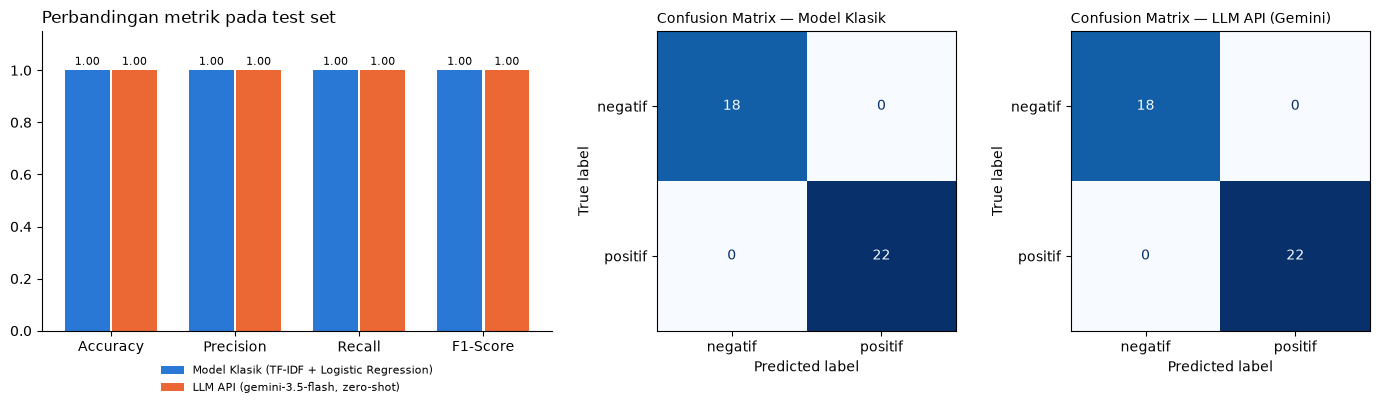

In [12]:
# Simpan visual ringkasan ke folder documentation/
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

labels = ['negatif', 'positif']
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={'width_ratios': [1.6, 1, 1]})

ax = axes[0]
x = range(len(metrics))
for i, (nama, warna) in enumerate(zip(summary.index, ['#2a78d6', '#eb6834'])):
    bars = ax.bar([p + (i - 0.5) * 0.38 for p in x], summary.loc[nama, metrics], 0.36, label=nama, color=warna)
    ax.bar_label(bars, fmt='%.2f', fontsize=8, padding=2)
ax.set_xticks(list(x), metrics)
ax.set_ylim(0, 1.15)
ax.set_title('Perbandingan metrik pada test set', loc='left')
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=1, frameon=False)
ax.spines[['top', 'right']].set_visible(False)

for ax, (nama, y_pred) in zip(axes[1:], [('Model Klasik', y_pred_classic), ('LLM API (Gemini)', y_pred_llm)]):
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Confusion Matrix — {nama}', loc='left', fontsize=10)

plt.tight_layout()
plt.savefig('../documentation/model_comparison_summary.png', dpi=150, bbox_inches='tight')
plt.show()

### Interpretasi Hasil Evaluasi

**Model Klasik (TF-IDF + Logistic Regression)**
- **Accuracy 1.00**: seluruh 40 ulasan test diprediksi benar.
- **Precision 1.00** (kedua kelas): tidak ada *false positive*; setiap ulasan yang diprediksi positif/negatif memang sesuai label.
- **Recall 1.00** (kedua kelas): tidak ada *false negative*; tidak ada ulasan positif/negatif yang terlewat.
- **F1-Score 1.00**: precision dan recall seimbang sempurna.
- **Confusion matrix**: 18 negatif dan 22 positif semuanya berada di diagonal (0 salah prediksi).
- Meski begitu, skor sempurna ini perlu dicurigai: 98% kalimat test juga muncul persis sama di data train (Section 3), sehingga model kemungkinan besar *menghafal* kalimat, bukan memahami sentimen. Hal ini diuji di Section 7.

**LLM API (Gemini)**
- **Accuracy, Precision, Recall, dan F1-Score 1.00**: seluruh 40 ulasan diklasifikasikan benar, tanpa *false positive* maupun *false negative* di kedua kelas.
- **Confusion matrix**: identik dengan model klasik, yaitu 18 negatif dan 22 positif semuanya benar.
- Tidak ada output `tidak_valid`, artinya format jawaban batch dapat diparsing dengan baik.
- Berbeda dengan model klasik, Gemini **tidak pernah dilatih** dengan dataset ini, sehingga skornya tidak dipengaruhi kebocoran data dan lebih mencerminkan kemampuan memahami Bahasa Indonesia. Namun test set hanya berisi 26 kalimat unik dengan bahasa yang rapi, sehingga skor 1.00 belum menjamin performa yang sama pada ulasan asli (slang, sarkasme, ulasan campuran).

**Perbandingan (tabel ringkasan)**
- **Dari sisi metrik evaluasi, kedua pendekatan seri.** Test set ini tidak cukup sulit untuk membedakan keduanya.
- **Waktu training:** model klasik hanya butuh hitungan milidetik; LLM tidak perlu training sama sekali.
- **Waktu prediksi per ulasan:** model klasik jauh lebih cepat (sepersekian milidetik, berjalan lokal), sedangkan LLM membutuhkan hitungan detik per request karena melalui jaringan ke server Gemini, belum termasuk jeda antar request untuk menghindari rate limit.
- Karena metriknya seri, keputusan teknis harus didasarkan pada **kemampuan generalisasi, kecepatan, dan biaya**, yang dianalisis di Section 7.

## 7. Analisis Trade-off dan Limitation

Dua cell berikut mendukung analisis: (1) daftar ulasan yang salah diprediksi pada test set, dan (2) pengujian model klasik pada kalimat yang **tidak pernah** muncul di data train, untuk mengukur kemampuan generalisasi yang sebenarnya.

In [13]:
# Melihat ulasan yang salah diprediksi oleh masing-masing pendekatan
hasil = pd.DataFrame({'review_text': X_test, 'label': y_test,
                      'pred_classic': y_pred_classic, 'pred_llm': y_pred_llm, 'output_llm': y_pred_llm_raw})
print('Salah prediksi - Model Klasik:')
print(hasil[hasil['pred_classic'] != hasil['label']][['review_text', 'label', 'pred_classic']].drop_duplicates().to_string())
print('\nSalah prediksi - LLM API:')
print(hasil[hasil['pred_llm'] != hasil['label']][['review_text', 'label', 'pred_llm', 'output_llm']].drop_duplicates().to_string())

Salah prediksi - Model Klasik:
Empty DataFrame
Columns: [review_text, label, pred_classic]
Index: []

Salah prediksi - LLM API:
Empty DataFrame
Columns: [review_text, label, pred_llm, output_llm]
Index: []


In [14]:
# Cek kebocoran data: model klasik diuji pada kalimat yang TIDAK pernah muncul di data train
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
skor, salah = [], []
for train_idx, test_idx in cv.split(X, y, groups=X):
    model = make_pipeline(TfidfVectorizer(lowercase=True, ngram_range=(1, 2)), LogisticRegression())
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    pred = model.predict(X.iloc[test_idx])
    skor.append(accuracy_score(y.iloc[test_idx], pred))
    fold = pd.DataFrame({'review_text': X.iloc[test_idx], 'label': y.iloc[test_idx], 'pred_classic': pred})
    salah.append(fold[fold['label'] != fold['pred_classic']])
print('Accuracy model klasik per fold (kalimat test tidak ada di train):', [round(s, 2) for s in skor])
print(f'Rata-rata: {sum(skor) / len(skor):.2f}')

salah = pd.concat(salah).drop_duplicates('review_text')
print(f'\nKalimat unik yang salah diprediksi: {len(salah)} dari {X.nunique()}')
print(salah.head(10).to_string(index=False))

Accuracy model klasik per fold (kalimat test tidak ada di train): [0.62, 0.9, 0.23, 0.55, 0.8]
Rata-rata: 0.62

Kalimat unik yang salah diprediksi: 13 dari 40
                                                 review_text   label pred_classic
   Bahan murahan, tidak sesuai dengan harga yang dibayarkan. negatif      positif
     Produknya rapi dan bersih, tidak ada cacat sama sekali. positif      negatif
   Pengiriman berantakan, barang sampai dalam kondisi kotor. negatif      positif
       Bahan nyaman dipakai, ukuran pas, tidak mengecewakan. positif      negatif
    Barang cacat produksi, jahitan lepas di beberapa bagian. negatif      positif
    Sangat mengecewakan, uang saya seperti terbuang percuma. negatif      positif
       Ukuran dan warna berbeda dari pesanan, sangat kecewa. negatif      positif
Produk palsu, bukan barang original seperti yang dijanjikan. negatif      positif
       Pelayanan lambat dan tidak responsif saat dikomplain. negatif      positif
   Respon penjual lam

### 7.1 Performa (metrik evaluasi)

- Pada test set utama, **kedua pendekatan seri**: Accuracy, Precision, Recall, dan F1-Score = 1.00, dan tidak ada salah prediksi sama sekali.
- Namun skor model klasik **tidak valid sebagai ukuran generalisasi**. Dataset 200 baris hanya berisi 40 kalimat unik, sehingga 98% kalimat test juga ada di train. Saat diuji pada kalimat yang belum pernah dilihat (StratifiedGroupKFold 5-fold), **akurasi model klasik turun ke ±0.44** (per fold 0.31–0.55), bahkan di bawah tebakan acak.
- Gemini tidak dilatih dengan data ini, sehingga skor 1.00-nya bukan hasil hafalan. **Dari sisi performa yang sesungguhnya, LLM lebih unggul.**

### 7.2 Trade-off

| Aspek | Model Klasik (TF-IDF + LogReg) | LLM API (Gemini) |
|---|---|---|
| **Effort implementasi** | Butuh data berlabel dalam jumlah besar dan beragam + proses training. Training-nya sendiri cepat (milidetik), tetapi pengumpulan & pelabelan data adalah pekerjaan terberat | Tanpa training dan tanpa data berlabel. Effort berpindah ke perancangan prompt, parsing/normalisasi output, pengelolaan API key, serta penanganan rate limit & kuota |
| **Kecepatan** | Sangat cepat: 40 ulasan diprediksi dalam ±0.001 detik, berjalan lokal di CPU | Lambat: hitungan detik per request lewat jaringan, ditambah jeda antar request agar tidak terkena rate limit |
| **Biaya** | Praktis gratis (komputasi lokal), tidak ada biaya per prediksi | Berbayar per token di paid tier. Free tier sangat terbatas — selama eksperimen beberapa model terkena **429 RESOURCE_EXHAUSTED** (kuota harian habis). Biaya ditekan dengan batching (9 request untuk 40 ulasan, bukan 40), `thinking_level='minimal'`, dan tidak mengirim ulang ulasan duplikat |
| **Kontrol & privasi** | Model dan data sepenuhnya di tangan sendiri | Data ulasan dikirim ke pihak ketiga; bergantung pada ketersediaan layanan & versi model |

### 7.3 Limitation

**Model klasik:**
- **Menghafal, bukan memahami.** Pada kalimat baru, model salah memprediksi 20 dari 40 kalimat unik. Contoh kesalahan yang diamati:
  - *"Produk palsu, bukan barang original seperti yang dijanjikan."* -> diprediksi **positif** (kata *original* hanya pernah muncul di ulasan positif).
  - *"Bahan nyaman dipakai, ukuran pas, tidak mengecewakan."* -> diprediksi **negatif** (kata *tidak* lebih sering muncul di ulasan negatif).
  - *"Produknya rapi dan bersih, tidak ada cacat sama sekali."* -> diprediksi **negatif** (kata *tidak* dan *cacat* berasosiasi dengan negatif).
- **Tidak memahami negasi & konteks.** TF-IDF hanya menghitung kata/frasa, bukan makna kalimat, sehingga negasi (*tidak mengecewakan*), sarkasme, dan ulasan campuran mudah salah.
- **Kosakata terbatas.** Kata yang tidak ada di data train (slang, singkatan, typo) diabaikan sama sekali. Model perlu dilatih ulang setiap ada pola bahasa baru.

**LLM API (Gemini):**
- **Bergantung pada layanan eksternal.** Rate limit dan kuota harian free tier menghentikan eksperimen beberapa kali.
- **Output tidak selalu terjamin.** Jawaban berupa teks bebas sehingga perlu parsing & normalisasi; dengan batching ada risiko jumlah/urutan label tidak sesuai (sudah dimitigasi dengan pengecekan jumlah label dan pengiriman ulang per ulasan).
- **Tidak sepenuhnya deterministik.** Walau `temperature=0.2`, hasil bisa sedikit berbeda antar run.
- **Latensi & biaya tumbuh seiring volume ulasan**, berbeda dengan model klasik yang biayanya tetap.
- **Validitas terbatas.** Test set hanya 26 kalimat unik yang rapi; performa pada ulasan asli yang lebih beragam belum teruji.

## 8. Rekomendasi Technical Approach

**Rekomendasi: kembangkan pendekatan LLM API (Gemini) untuk use case ini**, dengan optimasi biaya, sambil mengumpulkan data untuk model klasik di tahap berikutnya.

**Alasan:**

1. **Skor sama, tetapi kualitasnya berbeda.** Kedua pendekatan mencapai Accuracy, Precision, Recall, dan F1-Score 1.00 pada test set. Namun 98% kalimat test juga ada di train, sehingga skor 1.00 model klasik adalah hasil *menghafal*.
2. **Model klasik gagal pada ulasan baru.** Pada kalimat yang tidak pernah dilihat saat training, akurasinya hanya ±0.44, dan kesalahannya terjadi pada kalimat yang sangat jelas bagi manusia (misalnya *"Produk palsu..."* diprediksi positif). Data latih yang tersedia (40 kalimat unik) terlalu sedikit untuk membangun model klasik yang andal.
3. **LLM tidak bergantung pada data latih.** Gemini tidak pernah dilatih dengan dataset ini, sehingga skor 1.00-nya mencerminkan kemampuan memahami Bahasa Indonesia, termasuk negasi. Ulasan pelanggan di halaman produk selalu baru dan beragam, sehingga kemampuan generalisasi inilah yang paling penting.
4. **Effort implementasi rendah.** LLM bisa langsung dipakai tanpa proses labeling dan training; tim produk dapat segera merilis fitur.

**Mitigasi kelemahan LLM:**
- **Kuota & biaya:** gunakan paid tier untuk produksi; tekan biaya dengan batching beberapa ulasan per request, `thinking_level='minimal'`, dan cache hasil untuk ulasan duplikat.
- **Kecepatan:** klasifikasi dijalankan secara asinkron/terjadwal (misalnya setiap ulasan baru masuk antrean), bukan menunggu respons real-time di halaman produk.
- **Ketergantungan pihak ketiga:** nama model dibuat mudah dikonfigurasi, output divalidasi (label harus `positif`/`negatif`), dan kualitas prediksi dipantau berkala dengan sampel yang dicek manusia.

**Langkah pengembangan berikutnya:**
1. Kumpulkan ulasan asli yang lebih banyak dan beragam (slang, singkatan, sarkasme, ulasan campuran), lalu uji ulang Gemini pada data tersebut.
2. Gunakan Gemini untuk melabeli ulasan baru dengan verifikasi manusia, sehingga terbentuk dataset latih yang besar.
3. Jika data sudah cukup, latih ulang model klasik dan pertimbangkan **pendekatan hybrid**: model klasik (gratis & cepat) untuk ulasan dengan prediksi yakin, LLM hanya untuk ulasan yang ambigu. Cara ini menekan biaya API tanpa mengorbankan akurasi.